## Persiapan: Import library
Mengimpor pustaka untuk membaca data, membuat grafik, melakukan standardisasi, membangun model, serta mengevaluasi klaster.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score

plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['figure.dpi'] = 110

## Persiapan: Membaca dan memeriksa dataset


In [ ]:

file_csv = 'CC_Customer_Dataset.csv'

df = pd.read_csv(file_csv)
print('Ukuran dataset:', df.shape)
print('Missing values:', df.isna().sum().sum())
print('Duplikat:', df.duplicated().sum())
print('Kolom:', df.columns.tolist())
display(df.head())

Ukuran dataset: (660, 7)
Missing values: 0
Duplikat: 0
Kolom: ['Sl_No', 'Customer Key', 'Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


## Nomor 1 — Scatterplot dua variabel


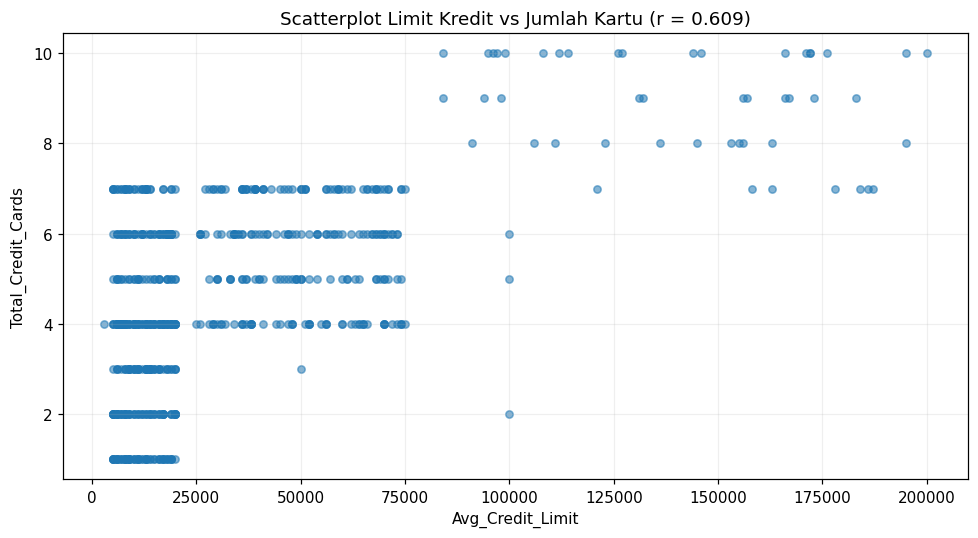

Korelasi Pearson: 0.609


In [ ]:
fitur_2 = ['Avg_Credit_Limit', 'Total_Credit_Cards']
x = df['Avg_Credit_Limit']
y = df['Total_Credit_Cards']
korelasi = df[fitur_2].corr().iloc[0, 1]

plt.figure(figsize=(9, 5))
plt.scatter(x, y, alpha=0.55, s=23)
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.title(f'Scatterplot Limit Kredit vs Jumlah Kartu (r = {korelasi:.3f})')
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig('JS07_1_scatter_awal.png', dpi=160)
plt.show()
print(f'Korelasi Pearson: {korelasi:.3f}')

**Analisis nomor 1:** Korelasi Pearson sekitar 0,609, artinya terdapat kecenderungan hubungan positif. Akan tetapi, titik-titik tidak membentuk garis lurus yang rapat; karena itu sebaran data tidak sepenuhnya linier. Jumlah kartu juga bernilai diskret (bilangan bulat).

## Nomor 2 — K-Means dan elbow method


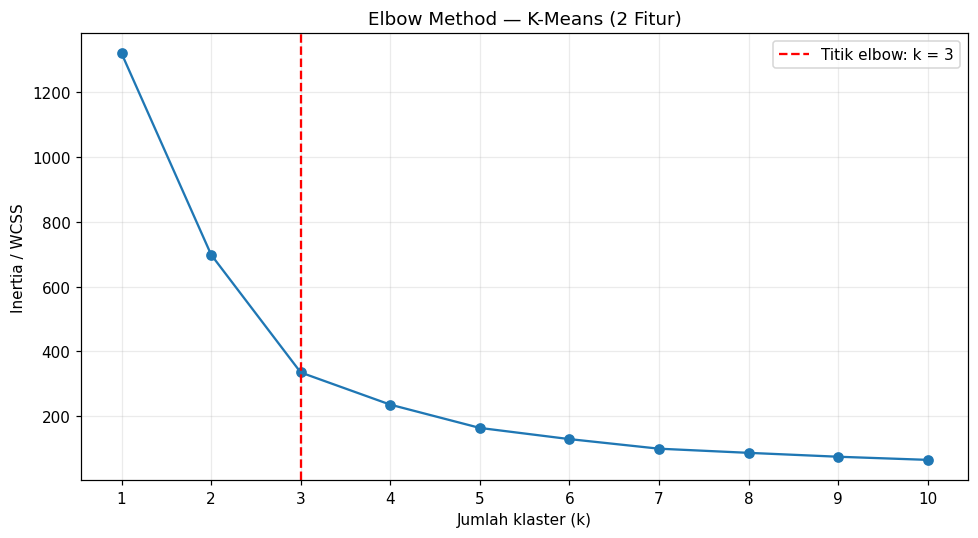

 k  Inertia
 1  1320.00
 2   698.29
 3   334.72
 4   235.39
 5   163.47
 6   128.96
 7    99.37
 8    86.53
 9    74.53
10    64.83


In [ ]:
scaler_2 = StandardScaler()
X_2 = scaler_2.fit_transform(df[fitur_2])

nilai_k = range(1, 11)
inertia = []
for k in nilai_k:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_2)
    inertia.append(model.inertia_)

plt.figure(figsize=(9, 5))
plt.plot(list(nilai_k), inertia, marker='o')
plt.axvline(3, color='red', linestyle='--', label='Titik elbow: k = 3')
plt.xticks(list(nilai_k))
plt.xlabel('Jumlah klaster (k)')
plt.ylabel('Inertia / WCSS')
plt.title('Elbow Method — K-Means (2 Fitur)')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig('JS07_2_elbow_kmeans.png', dpi=160)
plt.show()

print(pd.DataFrame({'k': list(nilai_k), 'Inertia': np.round(inertia, 2)}).to_string(index=False))

**Analisis nomor 2:** Titik siku (*elbow*) dipilih pada k = 3. Inertia menurun dari 698,29 (k=2) menjadi 334,72 (k=3), kemudian hanya menurun menjadi 235,39 (k=4). Setelah k=3, tambahan klaster memberi penurunan inertia yang relatif lebih kecil. Ini pilihan berdasarkan elbow method, bukan berdasarkan maksimum silhouette score.

## Nomor 3 — Hasil klasterisasi K-Means pada scatterplot
Model K-Means menggunakan k = 3

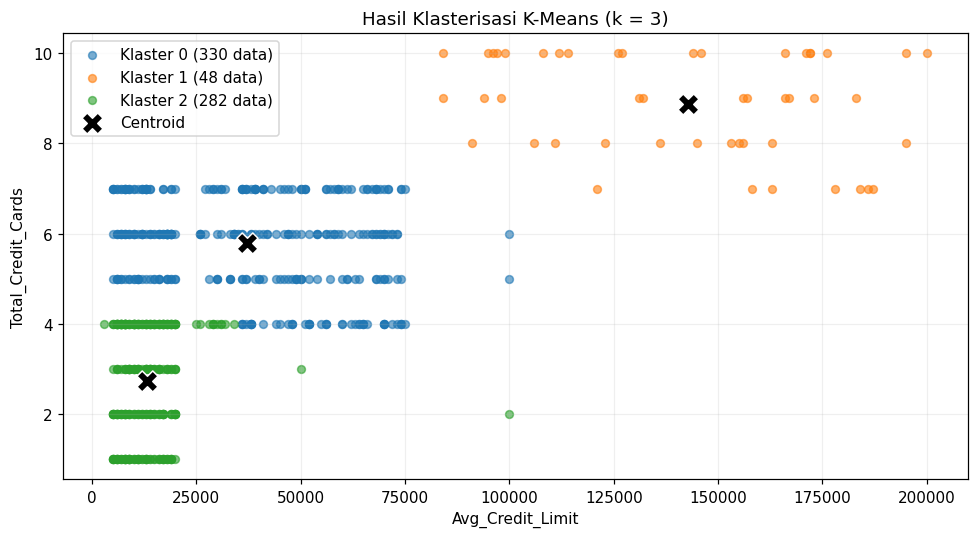

Jumlah anggota dan rata-rata fitur setiap klaster:


Avg_Credit_Limit            Total_Credit_Cards      
                          count       mean              count  mean
Klaster_KMeans                                                     
0                           330   37160.61                330  5.79
1                            48  142750.00                 48  8.88
2                           282   13134.75                282  2.73

Silhouette score K-Means (opsional): 0.4901


In [ ]:
k_terbaik = 3
kmeans = KMeans(n_clusters=k_terbaik, random_state=42, n_init=10)
label_kmeans = kmeans.fit_predict(X_2)
df['Klaster_KMeans'] = label_kmeans
pusat_asli = scaler_2.inverse_transform(kmeans.cluster_centers_)

plt.figure(figsize=(9, 5))
for klaster in sorted(np.unique(label_kmeans)):
    bagian = df[df['Klaster_KMeans'] == klaster]
    plt.scatter(bagian['Avg_Credit_Limit'], bagian['Total_Credit_Cards'],
                alpha=0.6, s=26, label=f'Klaster {klaster} ({len(bagian)} data)')
plt.scatter(pusat_asli[:, 0], pusat_asli[:, 1], color='black', marker='X',
            s=190, edgecolors='white', linewidths=1.0, label='Centroid')
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.title('Hasil Klasterisasi K-Means (k = 3)')
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig('JS07_3_scatter_kmeans.png', dpi=160)
plt.show()

print('Jumlah anggota dan rata-rata fitur setiap klaster:')
display(df.groupby('Klaster_KMeans')[fitur_2].agg(['count', 'mean']).round(2))
print('Silhouette score K-Means (opsional):', round(silhouette_score(X_2, label_kmeans), 4))

**Analisis nomor 3:** Klaster membedakan pelanggan dengan limit serta jumlah kartu relatif rendah, menengah, dan tinggi. Nomor label klaster (0/1/2) tidak menunjukkan peringkat; interpretasinya melihat rata-rata fitur yang dicetak di atas.

## Nomor 4 — DBSCAN menggunakan seluruh fitur yang relevan


In [ ]:
fitur_5 = ['Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank',
           'Total_visits_online', 'Total_calls_made']
X_5 = StandardScaler().fit_transform(df[fitur_5])
print('Fitur DBSCAN:', fitur_5)
print('Bentuk matriks fitur:', X_5.shape)

Fitur DBSCAN: ['Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']
Bentuk matriks fitur: (660, 5)


## Nomor 5 — Elbow untuk DBSCAN: k-distance graph


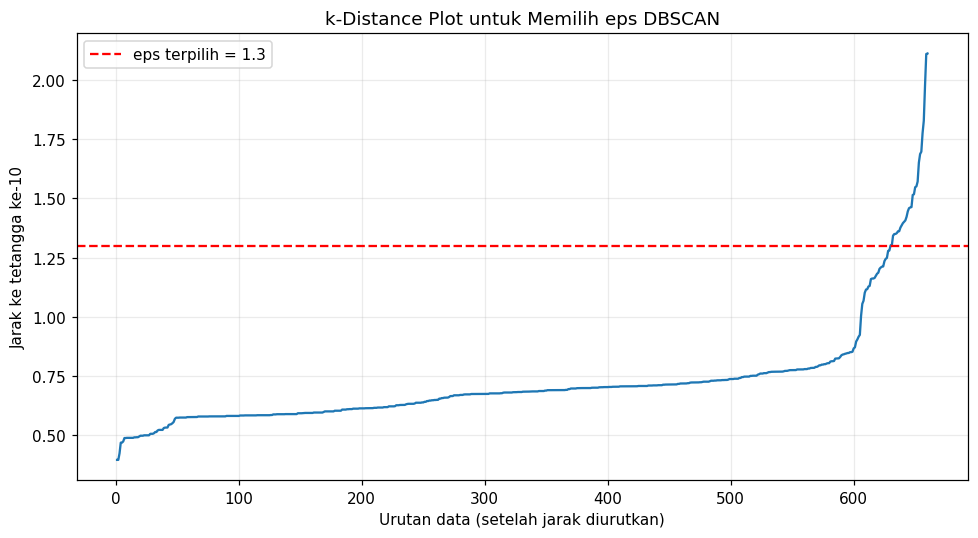

Perbandingan parameter DBSCAN:


,eps,Jumlah Klaster,Noise,Silhouette,DBI
0,1.0,1,53,NaN,NaN
1,1.1,3,33,0.5522,0.9102
2,1.2,2,13,0.5686,0.6074
3,1.3,2,9,0.5710,0.6141
4,1.4,2,3,0.5748,0.6242


In [ ]:
min_samples = 10
jarak_tetangga, _ = NearestNeighbors(n_neighbors=min_samples).fit(X_5).kneighbors(X_5)
k_distance = np.sort(jarak_tetangga[:, -1])

plt.figure(figsize=(9, 5))
plt.plot(np.arange(1, len(k_distance) + 1), k_distance)
plt.axhline(1.3, color='red', linestyle='--', label='eps terpilih = 1.3')
plt.xlabel('Urutan data (setelah jarak diurutkan)')
plt.ylabel(f'Jarak ke tetangga ke-{min_samples}')
plt.title('k-Distance Plot untuk Memilih eps DBSCAN')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig('JS07_5_kdistance_dbscan.png', dpi=160)
plt.show()

print('Perbandingan parameter DBSCAN:')
perbandingan = []
for eps_uji in [1.0, 1.1, 1.2, 1.3, 1.4]:
    label_uji = DBSCAN(eps=eps_uji, min_samples=min_samples).fit_predict(X_5)
    mask_uji = label_uji != -1
    jumlah_klaster = len(set(label_uji) - {-1})
    baris = {'eps': eps_uji, 'Jumlah Klaster': jumlah_klaster,
             'Noise': int((~mask_uji).sum())}
    if jumlah_klaster >= 2 and mask_uji.sum() > jumlah_klaster:
        baris['Silhouette'] = round(silhouette_score(X_5[mask_uji], label_uji[mask_uji]), 4)
        baris['DBI'] = round(davies_bouldin_score(X_5[mask_uji], label_uji[mask_uji]), 4)
    else:
        baris['Silhouette'] = np.nan
        baris['DBI'] = np.nan
    perbandingan.append(baris)
display(pd.DataFrame(perbandingan))

**Analisis nomor 5:** Pada bagian akhir grafik, jarak tetangga meningkat semakin tajam. Dicoba beberapa nilai eps; eps = 1,3, dengan min_samples = 10, dipilih sebagai kompromi karena menghasilkan 2 klaster dan 9 noise, dengan sebagian besar data tetap tergabung ke klaster. Pada DBSCAN, 2 klaster ini adalah hasil, bukan parameter yang dipilih sebagai k. Jika grafik menunjukkan siku lain, parameter dapat dibandingkan kembali dengan proporsi noise dan hasil evaluasi.

## Nomor 4 (hasil) — Membuat DBSCAN dengan seluruh fitur
Model akhir menggunakan eps = 1.3 dan min_samples = 10. Label -1 berarti noise

Jumlah data untuk setiap label:
Klaster_DBSCAN
-1      9
 0    608
 1     43
Name: count, dtype: int64

Rata-rata fitur pada masing-masing klaster:


,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
Klaster_DBSCAN,,,,,
-1,101777.78,7.00,0.33,11.89,2.00
0,25685.86,4.38,2.56,1.91,3.79
1,146186.05,8.81,0.65,10.44,1.05


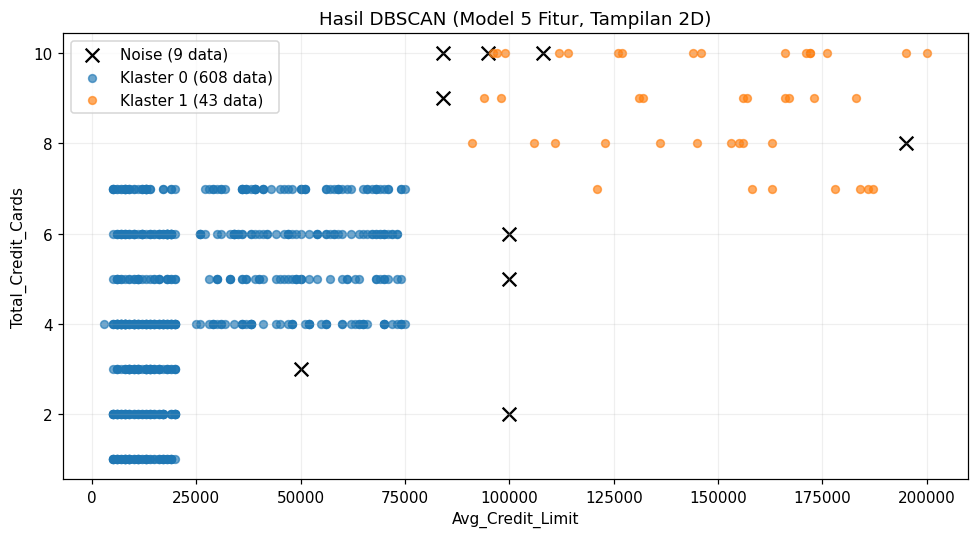

In [ ]:
dbscan = DBSCAN(eps=1.3, min_samples=10)
label_dbscan = dbscan.fit_predict(X_5)
df['Klaster_DBSCAN'] = label_dbscan

print('Jumlah data untuk setiap label:')
print(df['Klaster_DBSCAN'].value_counts().sort_index())
print('\nRata-rata fitur pada masing-masing klaster:')
display(df.groupby('Klaster_DBSCAN')[fitur_5].mean().round(2))

plt.figure(figsize=(9, 5))
for klaster in sorted(np.unique(label_dbscan)):
    bagian = df[df['Klaster_DBSCAN'] == klaster]
    if klaster == -1:
        plt.scatter(bagian['Avg_Credit_Limit'], bagian['Total_Credit_Cards'],
                    s=80, marker='x', color='black', label=f'Noise ({len(bagian)} data)')
    else:
        plt.scatter(bagian['Avg_Credit_Limit'], bagian['Total_Credit_Cards'],
                    alpha=0.65, s=26, label=f'Klaster {klaster} ({len(bagian)} data)')
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.title('Hasil DBSCAN (Model 5 Fitur, Tampilan 2D)')
plt.grid(alpha=0.2)
plt.legend()
plt.tight_layout()
plt.savefig('JS07_4_scatter_dbscan.png', dpi=160)
plt.show()

**Catatan visualisasi:** Scatterplot di atas hanya memperlihatkan 2 dari 5 fitur, tetapi label DBSCAN dihitung dari semua 5 fitur. Maka, kedekatan dua titik pada scatterplot belum tentu berarti dekat dalam ruang 5 dimensi.

## Nomor 6 — Silhouette score dan Davies-Bouldin Index (DBI)
Noise (-1) dikecualikan pada evaluasi kedua metrik supaya noise tidak dianggap sebagai satu klaster tersendiri. Kedua metrik dihitung pada matriks 5 fitur yang telah distandardisasi, bukan pada scatterplot 2D.

In [ ]:
bukan_noise = label_dbscan != -1
label_valid = label_dbscan[bukan_noise]
jumlah_klaster = len(np.unique(label_valid))

if jumlah_klaster >= 2 and jumlah_klaster < len(label_valid):
    silhouette = silhouette_score(X_5[bukan_noise], label_valid)
    dbi = davies_bouldin_score(X_5[bukan_noise], label_valid)
    print('Silhouette Score DBSCAN :', round(silhouette, 4))
    print('Davies-Bouldin Index   :', round(dbi, 4))
else:
    print('Metrik tidak dapat dihitung: jumlah klaster non-noise harus minimal 2.')
print('Jumlah klaster          :', jumlah_klaster)
print('Jumlah noise            :', (~bukan_noise).sum())
print('Data yang dievaluasi    :', bukan_noise.sum(), 'dari', len(df))

Silhouette Score DBSCAN : 0.571
Davies-Bouldin Index   : 0.6141
Jumlah klaster          : 2
Jumlah noise            : 9
Data yang dievaluasi    : 651 dari 660


**Analisis nomor 6:** Pada dataset ini, diperoleh silhouette score = 0,5710 dan DBI = 0,6141 untuk 651 data non-noise. Silhouette yang positif menunjukkan pemisahan klaster cukup jelas menurut metrik ini; DBI yang relatif rendah mengindikasikan klaster cukup kompak dan terpisah. 9 data noise tidak ikut perhitungan evaluasi. Nilai evaluasi dapat berubah jika eps, min_samples, atau preprocessing diubah.